<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HecktorGPT2CN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# HECKTOR GPT-2 CLASSIFIER
# HPV Status Prediction | Compact Single-Cell Notebook
# ============================================================

# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
import os, random, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42
def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. LOAD HECKTOR EXCEL DATA
DATA_FILE = "HPV2025.xlsx"
if not os.path.exists(DATA_FILE):
    downloaded = gdown.download(
        id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
        output=DATA_FILE, quiet=False
    )
    if downloaded is None or not os.path.exists(DATA_FILE):
        raise FileNotFoundError("Could not download HPV2025.xlsx.")

df = pd.read_excel(DATA_FILE)
TARGET = "HPV Status"
FEATURES = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "T-stage", "N-stage", "M-stage"
]
missing = [c for c in [TARGET] + FEATURES if c not in df.columns]
if missing:
    raise KeyError(f"Required Excel columns missing: {missing}")

# 3. ROBUSTLY NORMALISE TARGET AND SELECT FEATURES
def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"0", "0.0", "negative", "neg", "false", "no"}:
        return 0
    if s in {"1", "1.0", "positive", "pos", "true", "yes"}:
        return 1
    try:
        n = float(s)
        if n in (0, 1):
            return int(n)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[TARGET].apply(normalize_target)
invalid_count = int(df["HPV_Label"].isna().sum())
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[FEATURES + ["HPV_Label"]].copy()

if df.empty:
    raise ValueError("No recognised HPV labels found; check the target column.")
counts = df["HPV_Label"].value_counts().reindex([0, 1], fill_value=0)
if (counts < 2).any():
    raise ValueError(f"Insufficient examples for both HPV classes: {counts.to_dict()}")

print("Dataset:", df.shape, "| Invalid/missing target rows dropped:", invalid_count)
print("HPV classes (0=negative, 1=positive):\n", counts)

# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT (65/15/20)
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = [x.copy() for x in (train_df, val_df, test_df)]

# 5. IMPUTE MISSING FEATURES USING TRAINING DATA ONLY
fill_values = {}
for col in FEATURES:
    if pd.api.types.is_numeric_dtype(train_df[col]):
        value = train_df[col].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[col].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[col] = value
    for split in (train_df, val_df, test_df):
        split[col] = split[col].fillna(value)
        if split[col].dtype == object:
            split[col] = split[col].astype(str).replace(
                {"": "Unknown", "nan": "Unknown", "None": "Unknown"}
            )

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
for name, y in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name}: n={len(y)}, class counts={np.bincount(y, minlength=2)}")


# 6. CONVERT THE EIGHT CLINICAL FEATURES INTO TEXT PROMPTS

def display_value(x):
    if pd.isna(x):
        return "Unknown"
    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()


def format_stage(x, prefix):
    value = display_value(x)

    if value == "Unknown" or value.upper().startswith(prefix):
        return value

    try:
        n = float(value)
        if n.is_integer():
            return f"{prefix}{int(n)}"
    except ValueError:
        pass

    return f"{prefix}{value}"


def patient_to_text(row):

    age = display_value(row["Age"])
    gender = display_value(row["Gender"])
    tobacco = display_value(row["Tobacco Consumption"])
    alcohol = display_value(row["Alcohol Consumption"])
    performance = display_value(row["Performance Status"])

    t_stage = format_stage(row["T-stage"], "T")
    n_stage = format_stage(row["N-stage"], "N")
    m_stage = format_stage(row["M-stage"], "M")

    return (
        f"This patient is a {age}-year-old {gender}. "
        f"Tobacco consumption is {tobacco}. "
        f"Alcohol consumption is {alcohol}. "
        f"Performance status is {performance}. "
        f"Tumour stage is {t_stage}. "
        f"Nodal stage is {n_stage}. "
        f"Metastatic stage is {m_stage}. "
        "Predict whether the patient is HPV positive or HPV negative."
    )


train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]

# 7. LOAD TOKENIZER AND SET TRAINING PARAMETERS
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
lengths = [len(tokenizer.encode(t, add_special_tokens=False)) for t in train_texts]
MAX_LENGTH = min(1024, max(32, int(np.ceil(max(lengths) / 8) * 8)))
BATCH_SIZE, EPOCHS = 64, 500
LEARNING_RATE, WEIGHT_DECAY, DROPOUT = 1e-3, 1e-4, 0.1
print("Max prompt length:", max(lengths), "| MAX_LENGTH:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)

# 8. BUILD DATASETS AND DATA LOADERS
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            enc = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                enc["input_ids"].squeeze(0),
                enc["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, label = self.items[i]
        return {"input_ids": ids, "attention_mask": mask,
                "label": torch.tensor(label, dtype=torch.long)}

train_ds = HPVTextDataset(train_texts, y_train)
val_ds = HPVTextDataset(val_texts, y_val)
test_ds = HPVTextDataset(test_texts, y_test)
loader_args = {
    "batch_size": BATCH_SIZE, "num_workers": 0,
    "pin_memory": torch.cuda.is_available()
}
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, shuffle=True, generator=generator, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS
class HPVNetGPT2Text(nn.Module):
    def __init__(self):
        super().__init__()
        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)

        # Freeze the entire GPT-2 backbone
        for param in self.gpt2.parameters():
            param.requires_grad = False

        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        h = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(h),
            nn.Dropout(DROPOUT),
            nn.Linear(h, 128),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):
        out = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        ).last_hidden_state

        positions = attention_mask.sum(dim=1) - 1
        pooled = out[
            torch.arange(out.size(0), device=out.device),
            positions
        ]
        return self.classifier(pooled)


model = HPVNetGPT2Text().to(device)

class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

def weighted_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()

# Train only the classification head
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# 10. VALIDATION SCORING AND THRESHOLD SELECTION
def get_scores(loader):
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
            logits = model(ids, mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels.extend(batch["label"].numpy())
    return np.asarray(scores), np.asarray(labels, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total, n_total = 0.0, 0
    with torch.no_grad():
        for b in loader:
            ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
            labels = b["label"].to(device)
            loss = weighted_loss(model(ids, mask), labels)
            n = len(labels); total += loss.item() * n; n_total += n
    return total / max(n_total, 1)

def choose_threshold(scores, labels):
    thresholds = np.unique(np.r_[0.0, scores, 1.0])
    values = [(float(t), balanced_accuracy_score(labels, scores >= t)) for t in thresholds]
    return max(values, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# 11. TRAIN MODEL AND SAVE BEST VALIDATION CHECKPOINTS
from pathlib import Path

OUT_DIR = Path("/content/drive/MyDrive/HECKTOR_GPT2_Discriminative_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy": OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": float("inf"), "Validation_ROC_AUC": -float("inf"),
    "Validation_PR_AUC": -float("inf"), "Validation_Balanced_Accuracy": -float("inf")
}
best_info, history = {}, []

for epoch in range(1, EPOCHS + 1):
    model.train()
    model.gpt2.eval()
    loss_sum, n_sum = 0.0, 0
    for b in train_loader:
        ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
        labels = b["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = weighted_loss(model(ids, mask), labels)
        loss.backward()
        optimizer.step()
        n = len(labels); loss_sum += loss.item() * n; n_sum += n

    train_loss = loss_sum / max(n_sum, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    threshold, val_ba = choose_threshold(val_scores, val_labels)
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap, "Validation_Balanced_Accuracy": val_ba
    }
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss, **metrics,
        "Validation_Threshold": threshold
    })

    for name, value in metrics.items():
        improved = value < best[name] if name == "Validation_Loss" else value > best[name]
        if improved:
            best[name] = float(value)
            best_info[name] = {"epoch": epoch, "value": float(value), "threshold": threshold}
            torch.save(model.state_dict(), paths[name])

    if epoch % 50 == 0:
        print(f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
              f"Val Loss={val_loss:.4f} | ROC-AUC={val_auc:.4f} | "
              f"PR-AUC={val_ap:.4f} | BA={val_ba:.4f} | Threshold={threshold:.4f}")

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
pd.DataFrame([
    {"Checkpoint": k, **v, "Path": str(paths[k])} for k, v in best_info.items()
]).to_csv(OUT_DIR / "best_validation_checkpoints.csv", index=False)

# 12. EVALUATE ALL CHECKPOINTS ON HELD-OUT TEST SET
results, predictions_by_model = [], {}
for name, path in paths.items():
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_scores(test_loader)
    threshold = best_info[name]["threshold"]
    preds = (scores >= threshold).astype(int)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, zero_division=0)
    cm = confusion_matrix(labels, preds, labels=[0, 1])

    print(f"\n=== {name} | Best epoch {best_info[name]['epoch']} | Threshold {threshold:.4f} ===")
    print(classification_report(
        labels, preds, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"], digits=4, zero_division=0
    ))
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    print(f"Test ROC-AUC={auc:.4f} | PR-AUC={ap:.4f} | BA={ba:.4f} | F1={f1:.4f}")

    results.append({
        "Dataset": "HECKTOR", "Model": "GPT-2 Classifier",
        "Checkpoint_Selected_By": name, "Best_Epoch": best_info[name]["epoch"],
        "Validation_Threshold": threshold, "Test_ROC_AUC": auc,
        "Test_PR_AUC": ap, "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]
    })
    predictions_by_model[name] = (labels, scores, preds, threshold)
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": preds, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{name.lower()}.csv", index=False)

results_df = pd.DataFrame(results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)

# 13. SAVE ROC AND PRECISION-RECALL CURVES
for name, (labels, scores, preds, threshold) in predictions_by_model.items():
    safe = name.lower()
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)

    pd.DataFrame({"FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds}).to_csv(
        OUT_DIR / f"roc_coordinates_{safe}.csv", index=False
    )
    pd.DataFrame({"Precision": precision, "Recall": recall}).to_csv(
        OUT_DIR / f"pr_coordinates_{safe}.csv", index=False
    )

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"HECKTOR ROC — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"roc_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"AP={ap:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"HECKTOR Precision-Recall — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"pr_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

# 14. SAVE SETTINGS AND COMPARISON RESULTS
settings = {
    "Dataset": "HECKTOR", "Model": MODEL_NAME, "Target": "HPV Status",
    "Features": ", ".join(FEATURES), "Number_of_Features": len(FEATURES),
    "Split": "65/15/20 stratified", "Seed": SEED, "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE, "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY, "Dropout": DROPOUT,
    "Max_Length": MAX_LENGTH, "Optimizer": "AdamW",
    "Class_Weighted_Loss": True, "GPT2_Backbone_Frozen": True,
    "Checkpoint_Selection": "Validation loss, ROC-AUC, PR-AUC, balanced accuracy",
    "Threshold_Selection": "Maximum validation balanced accuracy"
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC", "Test_Balanced_Accuracy", "Test_F1"
]]
if comparison_file.exists():
    old = pd.read_csv(comparison_file)
    combined = pd.concat([old, comparison], ignore_index=True, sort=False)
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison
combined.to_csv(comparison_file, index=False)

print("\nAll outputs saved to:", OUT_DIR.resolve())
print("Comparison CSV:", comparison_file.resolve())

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 18.5MB/s]


Dataset: (588, 9) | Invalid/missing target rows dropped: 138
HPV classes (0=negative, 1=positive):
 HPV_Label
0     58
1    530
Name: count, dtype: int64
Train: n=381, class counts=[ 37 344]
Validation: n=89, class counts=[ 9 80]
Test: n=118, class counts=[ 12 106]


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable parameters: 100226
Trainable parameters: 100226
Epoch 50/500 | Train Loss=0.6867 | Val Loss=0.6946 | ROC-AUC=0.8042 | PR-AUC=0.9727 | BA=0.7701 | Threshold=0.5226
Epoch 100/500 | Train Loss=0.6427 | Val Loss=0.6593 | ROC-AUC=0.8014 | PR-AUC=0.9720 | BA=0.7764 | Threshold=0.4679
Epoch 150/500 | Train Loss=0.6230 | Val Loss=0.6117 | ROC-AUC=0.7944 | PR-AUC=0.9701 | BA=0.7764 | Threshold=0.4975
Epoch 200/500 | Train Loss=0.5623 | Val Loss=0.5856 | ROC-AUC=0.8014 | PR-AUC=0.9726 | BA=0.7701 | Threshold=0.4964
Epoch 250/500 | Train Loss=0.6731 | Val Loss=0.5929 | ROC-AUC=0.7847 | PR-AUC=0.9703 | BA=0.7889 | Threshold=0.3629
Epoch 300/500 | Train Loss=0.5354 | Val Loss=0.5833 | ROC-AUC=0.7833 | PR-AUC=0.9703 | BA=0.7889 | Threshold=0.5110
Epoch 350/500 | Train Loss=0.5514 | Val Loss=0.6007 | ROC-AUC=0.7764 | PR-AUC=0.9690 | BA=0.7764 | Threshold=0.5563
Epoch 400/500 | Train Loss=0.5388 | Val Loss=0.5799 | ROC-AUC=0.7764 | PR-AUC=0.9692 | BA=0.7701 | Threshold=0.4261
Epoch 450/500 |

In [3]:
# ============================================================
# 95% BOOTSTRAP CONFIDENCE INTERVALS
# EPOCH 301 — HELD-OUT TEST SET
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

N_BOOTSTRAPS = 5000
CONFIDENCE_LEVEL = 0.95
RANDOM_STATE = 42

y_true = np.asarray(test_labels)
y_score = np.asarray(test_scores)

# Separate the two classes for stratified resampling
negative_scores = y_score[y_true == 0]
positive_scores = y_score[y_true == 1]

if len(negative_scores) == 0 or len(positive_scores) == 0:
    raise ValueError("Both classes must be present in the test set.")

rng = np.random.default_rng(RANDOM_STATE)

bootstrap_roc_auc = []
bootstrap_pr_auc = []

for i in range(N_BOOTSTRAPS):

    # Sample within each class, retaining the original class counts
    sampled_negative = rng.choice(
        negative_scores,
        size=len(negative_scores),
        replace=True
    )

    sampled_positive = rng.choice(
        positive_scores,
        size=len(positive_scores),
        replace=True
    )

    sampled_scores = np.concatenate([
        sampled_negative,
        sampled_positive
    ])

    sampled_labels = np.concatenate([
        np.zeros(len(sampled_negative), dtype=int),
        np.ones(len(sampled_positive), dtype=int)
    ])

    bootstrap_roc_auc.append(
        roc_auc_score(sampled_labels, sampled_scores)
    )

    bootstrap_pr_auc.append(
        average_precision_score(sampled_labels, sampled_scores)
    )

alpha = 1 - CONFIDENCE_LEVEL

def bootstrap_ci(values):
    lower = np.quantile(values, alpha / 2)
    upper = np.quantile(values, 1 - alpha / 2)
    return float(lower), float(upper)

roc_lower, roc_upper = bootstrap_ci(bootstrap_roc_auc)
pr_lower, pr_upper = bootstrap_ci(bootstrap_pr_auc)

print("===== EPOCH 301: 95% BOOTSTRAP CONFIDENCE INTERVALS =====")

print(
    f"ROC-AUC: {roc_auc_score(y_true, y_score):.4f} "
    f"(95% CI: {roc_lower:.4f}–{roc_upper:.4f})"
)

print(
    f"PR-AUC: {average_precision_score(y_true, y_score):.4f} "
    f"(95% CI: {pr_lower:.4f}–{pr_upper:.4f})"
)

ci_results = pd.DataFrame({
    "Metric": ["ROC-AUC", "PR-AUC"],
    "Estimate": [
        roc_auc_score(y_true, y_score),
        average_precision_score(y_true, y_score)
    ],
    "95% CI Lower": [roc_lower, pr_lower],
    "95% CI Upper": [roc_upper, pr_upper]
})

ci_results.to_csv(
    Path(OUT_DIR) / "epoch301_bootstrap_confidence_intervals.csv",
    index=False
)

display(ci_results)

===== EPOCH 301: 95% BOOTSTRAP CONFIDENCE INTERVALS =====
ROC-AUC: 0.8381 (95% CI: 0.7319–0.9277)
PR-AUC: 0.9792 (95% CI: 0.9637–0.9918)


,Metric,Estimate,95% CI Lower,95% CI Upper
0,ROC-AUC,0.838050,0.731918,0.927673
1,PR-AUC,0.979162,0.963665,0.991774


Number of test samples: 118


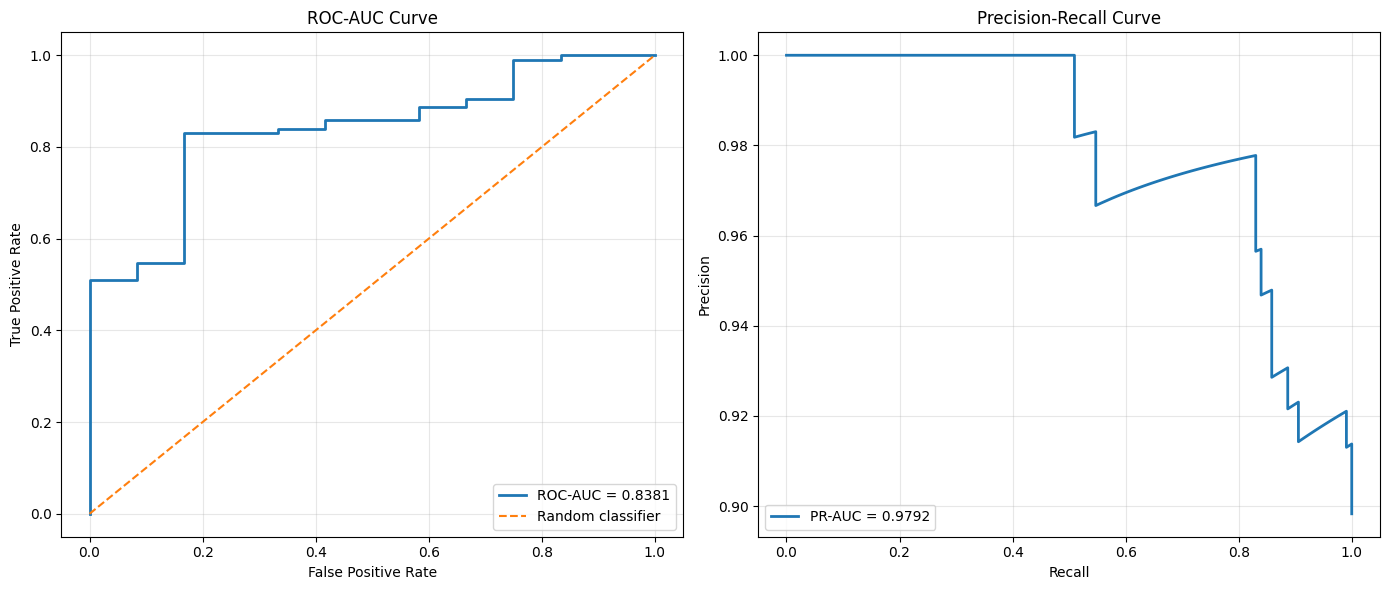

Test ROC-AUC: 0.8381
Test PR-AUC:  0.9792


In [14]:

import numpy as np
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# ==========================================
# 1. Generate predictions
# ==========================================

model.eval()

y_true = []
y_scores = []

with torch.no_grad():
    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        # Correct key: label (singular)
        labels = batch["label"]

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(outputs, dim=1)[:, 1]

        y_true.extend(labels.cpu().numpy())
        y_scores.extend(probabilities.cpu().numpy())

y_true = np.array(y_true)
y_scores = np.array(y_scores)

print("Number of test samples:", len(y_true))

# ==========================================
# 2. Calculate ROC-AUC
# ==========================================

fpr, tpr, _ = roc_curve(y_true, y_scores)
roc_auc = roc_auc_score(y_true, y_scores)

# ==========================================
# 3. Calculate PR-AUC
# ==========================================

precision, recall, _ = precision_recall_curve(
    y_true, y_scores
)

pr_auc = average_precision_score(y_true, y_scores)

# ==========================================
# 4. Plot ROC-AUC and PR-AUC curves
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ROC curve
axes[0].plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC-AUC Curve")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# PR curve
axes[1].plot(
    recall,
    precision,
    linewidth=2,
    label=f"PR-AUC = {pr_auc:.4f}"
)

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Save publication-quality figure
plt.savefig(
    "ROC_PR_AUC_epoch301.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 5. Print AUC values
# ==========================================

print(f"Test ROC-AUC: {roc_auc:.4f}")
print(f"Test PR-AUC:  {pr_auc:.4f}")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Checkpoint selected: Validation_ROC_AUC
Output directory: /content/drive/MyDrive/HECKTOR_GPT2_Discriminative_results/SHAP_LIME


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded checkpoint from: /content/drive/MyDrive/HECKTOR_GPT2_Discriminative_results/best_model_validation_roc_auc.pth
Best epoch: 180
Training matrix: (381, 8)
Validation matrix: (89, 8)

Calculating SHAP values...


PermutationExplainer explainer: 90it [00:23,  2.19it/s]


Generating SHAP beeswarm plot...


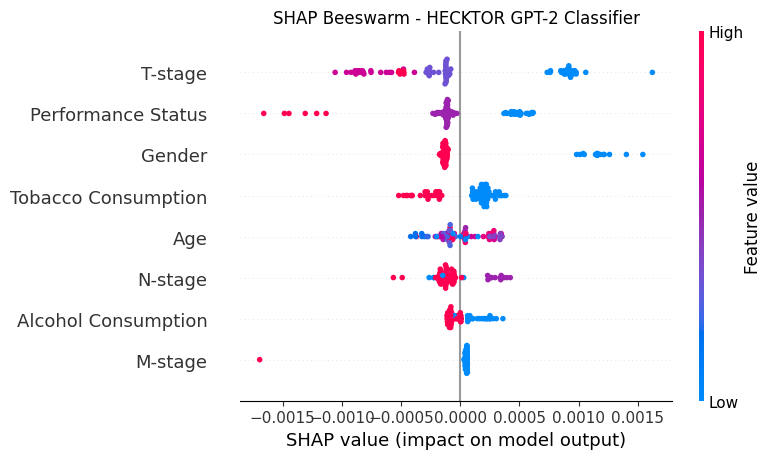


SHAP feature importance:
            Feature  Mean_Absolute_SHAP
            T-stage            0.000576
 Performance Status            0.000312
             Gender            0.000308
Tobacco Consumption            0.000234
                Age            0.000161
            N-stage            0.000156
Alcohol Consumption            0.000097
            M-stage            0.000071


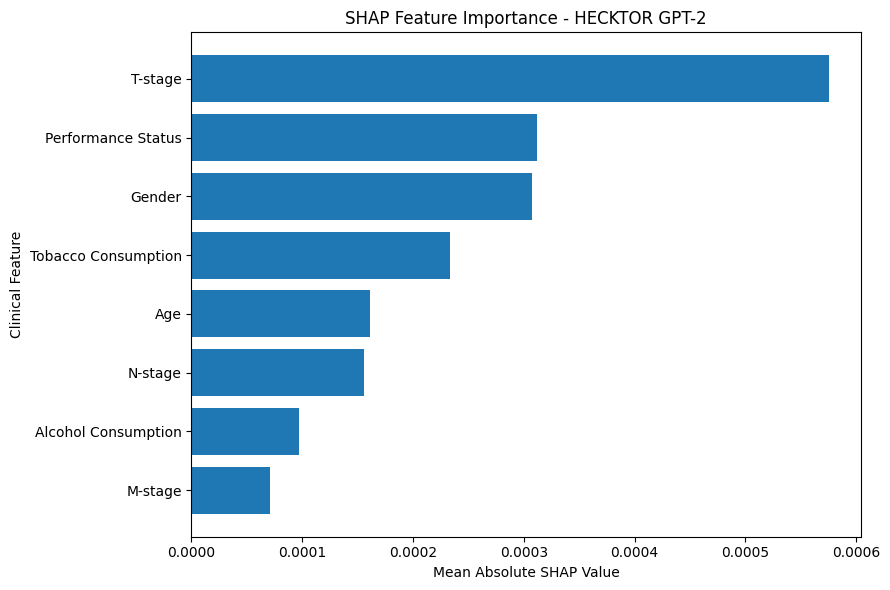


Generating LIME explanations...
Explaining validation patient 1/20


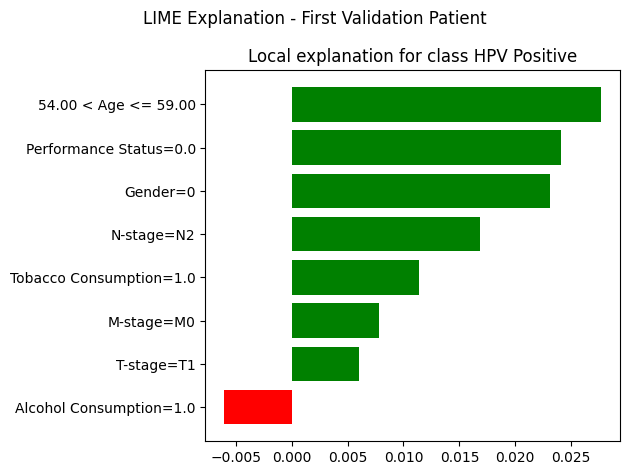

Explaining validation patient 2/20
Explaining validation patient 3/20
Explaining validation patient 4/20
Explaining validation patient 5/20
Explaining validation patient 6/20
Explaining validation patient 7/20
Explaining validation patient 8/20
Explaining validation patient 9/20
Explaining validation patient 10/20
Explaining validation patient 11/20
Explaining validation patient 12/20
Explaining validation patient 13/20
Explaining validation patient 14/20
Explaining validation patient 15/20
Explaining validation patient 16/20
Explaining validation patient 17/20
Explaining validation patient 18/20
Explaining validation patient 19/20
Explaining validation patient 20/20


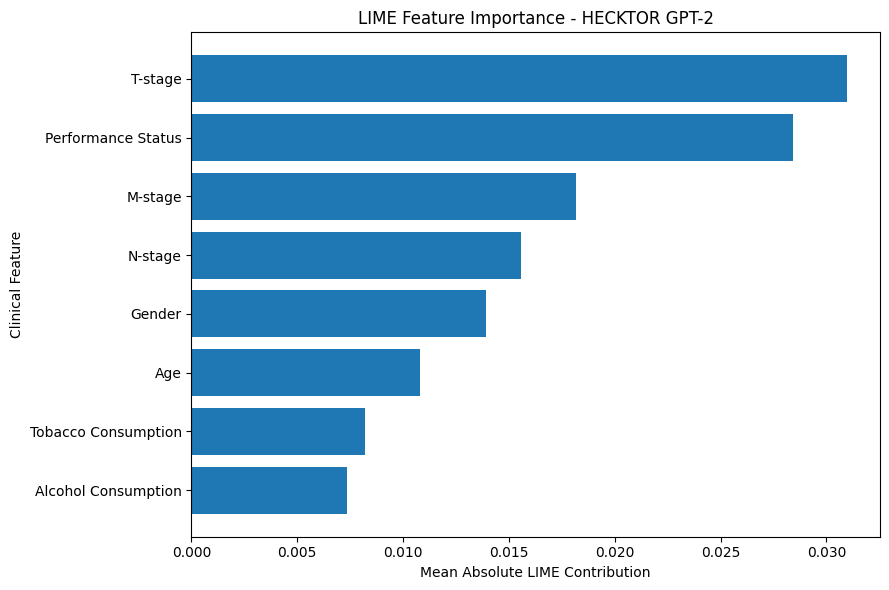


SHAP feature importance:
            Feature  Mean_Absolute_SHAP
            T-stage            0.000576
 Performance Status            0.000312
             Gender            0.000308
Tobacco Consumption            0.000234
                Age            0.000161
            N-stage            0.000156
Alcohol Consumption            0.000097
            M-stage            0.000071

LIME feature importance:
            Feature  Mean_Absolute_Contribution  Mean_Signed_Contribution
Alcohol Consumption                    0.007342                  0.004187
Tobacco Consumption                    0.008187                  0.006026
                Age                    0.010808                  0.009630
             Gender                    0.013929                  0.003825
            N-stage                    0.015565                  0.011923
            M-stage                    0.018151                  0.014852
 Performance Status                    0.028417                  0.024

In [18]:

# ============================================================
# HECKTOR GPT-2 CLASSIFIER
# SHAP AND LIME EXPLAINABILITY
# SINGLE STRATIFIED 65/15/20 SPLIT
# ============================================================

!pip install -q shap lime

import shap
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch

# ============================================================
# 1. SETTINGS AND OUTPUT DIRECTORY
# ============================================================

EXPLAIN_DIR = OUT_DIR / "SHAP_LIME"
EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)

# Select which saved checkpoint to explain
CHECKPOINT_TO_EXPLAIN = "Validation_ROC_AUC"

LIME_PATIENTS = 20
LIME_NUM_SAMPLES = 500

print("Checkpoint selected:", CHECKPOINT_TO_EXPLAIN)
print("Output directory:", EXPLAIN_DIR)

# Check required variables
required_variables = [
    "FEATURES", "train_df", "val_df", "paths",
    "best_info", "HPVNetGPT2Text", "patient_to_text",
    "tokenizer", "device", "MAX_LENGTH"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Run the training notebook first. Missing: {missing_variables}"
    )

# ============================================================
# 2. LOAD THE SELECTED MODEL CHECKPOINT
# ============================================================

model = HPVNetGPT2Text().to(device)

checkpoint_path = paths[CHECKPOINT_TO_EXPLAIN]

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model.eval()

print(
    "Loaded checkpoint from:",
    checkpoint_path
)

print(
    "Best epoch:",
    best_info[CHECKPOINT_TO_EXPLAIN]["epoch"]
)

# ============================================================
# 3. PREPARE THE EIGHT CLINICAL FEATURES
# ============================================================

# Age is treated as continuous.
# The remaining clinical features are treated as categorical.
numeric_features = ["Age"]

categorical_features = [
    col for col in FEATURES
    if col not in numeric_features
]

category_maps = {}

for col in categorical_features:

    categories = sorted(
        train_df[col].astype(str).unique().tolist()
    )

    if "Unknown" not in categories:
        categories.append("Unknown")

    category_maps[col] = categories

categorical_indices = [
    FEATURES.index(col)
    for col in categorical_features
]

categorical_names = {
    FEATURES.index(col): category_maps[col]
    for col in categorical_features
}

# ============================================================
# 4. ENCODE CLINICAL FEATURES
# ============================================================

def encode_features(data):

    encoded = np.zeros(
        (len(data), len(FEATURES)),
        dtype=float
    )

    for j, col in enumerate(FEATURES):

        if col in numeric_features:

            encoded[:, j] = pd.to_numeric(
                data[col], errors="coerce"
            ).fillna(0).to_numpy()

        else:

            mapping = {
                value: i
                for i, value in enumerate(category_maps[col])
            }

            encoded[:, j] = (
                data[col].astype(str)
                .map(mapping)
                .fillna(mapping["Unknown"])
                .to_numpy()
            )

    return encoded


def decode_features(encoded):

    encoded = np.asarray(encoded)

    if encoded.ndim == 1:
        encoded = encoded.reshape(1, -1)

    decoded = {}

    for j, col in enumerate(FEATURES):

        if col in numeric_features:

            decoded[col] = encoded[:, j].astype(float)

        else:

            categories = category_maps[col]

            codes = np.rint(
                encoded[:, j]
            ).astype(int)

            codes = np.clip(
                codes, 0, len(categories) - 1
            )

            decoded[col] = [
                categories[k] for k in codes
            ]

    return pd.DataFrame(
        decoded,
        columns=FEATURES
    )


train_matrix = encode_features(train_df[FEATURES])
val_matrix = encode_features(val_df[FEATURES])

print("Training matrix:", train_matrix.shape)
print("Validation matrix:", val_matrix.shape)

# ============================================================
# 5. MODEL PREDICTION FUNCTIONS
# ============================================================

def predict_positive(data):

    data = decode_features(data)

    texts = [
        patient_to_text(row)
        for _, row in data.iterrows()
    ]

    probabilities = []

    model.eval()

    with torch.no_grad():

        for start in range(0, len(texts), 16):

            batch_texts = texts[start:start + 16]

            enc = tokenizer(
                batch_texts,
                max_length=MAX_LENGTH,
                padding="max_length",
                truncation=True,
                return_tensors="pt"
            )

            input_ids = enc["input_ids"].to(device)
            attention_mask = enc["attention_mask"].to(device)

            logits = model(
                input_ids,
                attention_mask
            )

            probs = torch.softmax(
                logits, dim=1
            )[:, 1].cpu().numpy()

            probabilities.extend(probs)

    return np.asarray(probabilities)


def predict_proba(data):

    positive = predict_positive(data)

    return np.column_stack([
        1 - positive,
        positive
    ])

# ============================================================
# 6. SHAP EXPLANATION
# ============================================================

print("\nCalculating SHAP values...")

# Use training patients as background
background = train_matrix[
    :min(40, len(train_matrix))
]

masker = shap.maskers.Independent(
    background,
    max_samples=len(background)
)

explainer = shap.Explainer(
    predict_positive,
    masker,
    algorithm="permutation",
    feature_names=FEATURES
)

shap_values = explainer(
    val_matrix,
    max_evals=2 * len(FEATURES) + 1
)

# ------------------------------------------------------------
# SHAP BEESWARM PLOT
# ------------------------------------------------------------

print("Generating SHAP beeswarm plot...")

shap.plots.beeswarm(
    shap_values,
    max_display=len(FEATURES),
    show=False
)

plt.title(
    "SHAP Beeswarm - HECKTOR GPT-2 Classifier"
)

plt.tight_layout()

plt.savefig(
    EXPLAIN_DIR / "SHAP_Beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# SHAP FEATURE IMPORTANCE
# ------------------------------------------------------------

shap_importance = pd.DataFrame({
    "Feature": FEATURES,
    "Mean_Absolute_SHAP": np.abs(
        shap_values.values
    ).mean(axis=0)
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

shap_importance.to_csv(
    EXPLAIN_DIR / "SHAP_Feature_Importance.csv",
    index=False
)

print("\nSHAP feature importance:")
print(shap_importance.to_string(index=False))

# ------------------------------------------------------------
# SHAP BAR PLOT
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.barh(
    shap_importance["Feature"].iloc[::-1],
    shap_importance["Mean_Absolute_SHAP"].iloc[::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Clinical Feature")

plt.title(
    "SHAP Feature Importance - HECKTOR GPT-2"
)

plt.tight_layout()

plt.savefig(
    EXPLAIN_DIR / "SHAP_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# 7. LIME EXPLANATIONS
# ============================================================

print("\nGenerating LIME explanations...")

lime_explainer = LimeTabularExplainer(
    training_data=train_matrix,
    feature_names=FEATURES,
    class_names=[
        "HPV Negative",
        "HPV Positive"
    ],
    categorical_features=categorical_indices,
    categorical_names=categorical_names,
    mode="classification",
    discretize_continuous=True,
    random_state=SEED
)

number_of_patients = min(
    LIME_PATIENTS,
    len(val_matrix)
)

all_lime_results = []

for patient_index in range(number_of_patients):

    print(
        f"Explaining validation patient "
        f"{patient_index + 1}/{number_of_patients}"
    )

    lime_exp = lime_explainer.explain_instance(
        val_matrix[patient_index],
        predict_proba,
        num_features=len(FEATURES),
        num_samples=LIME_NUM_SAMPLES,
        labels=[1]
    )

    # Save individual feature contributions
    for feature_index, contribution in lime_exp.as_map()[1]:

        all_lime_results.append({
            "Patient": patient_index + 1,
            "Feature": FEATURES[feature_index],
            "HPV_Positive_Contribution": contribution
        })

    # Save the first patient's individual LIME plot
    if patient_index == 0:

        fig = lime_exp.as_pyplot_figure(label=1)

        fig.suptitle(
            "LIME Explanation - First Validation Patient"
        )

        fig.tight_layout()

        fig.savefig(
            EXPLAIN_DIR / "LIME_First_Patient.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

# ============================================================
# 8. COMBINE LIME RESULTS
# ============================================================

lime_df = pd.DataFrame(all_lime_results)

lime_summary = (
    lime_df.assign(
        Absolute_Contribution=
        lime_df["HPV_Positive_Contribution"].abs()
    )
    .groupby("Feature")
    .agg(
        Mean_Absolute_Contribution=(
            "Absolute_Contribution", "mean"
        ),
        Mean_Signed_Contribution=(
            "HPV_Positive_Contribution", "mean"
        )
    )
    .reset_index()
    .sort_values(
        "Mean_Absolute_Contribution",
        ascending=True
    )
)

# Save patient-level explanations
lime_df.to_csv(
    EXPLAIN_DIR / "LIME_All_Patient_Results.csv",
    index=False
)

# Save combined feature importance
lime_summary.to_csv(
    EXPLAIN_DIR / "LIME_Combined_Feature_Importance.csv",
    index=False
)

# ============================================================
# 9. COMBINED LIME FEATURE IMPORTANCE PLOT
# ============================================================

plt.figure(figsize=(9, 6))

plt.barh(
    lime_summary["Feature"],
    lime_summary["Mean_Absolute_Contribution"]
)

plt.xlabel("Mean Absolute LIME Contribution")
plt.ylabel("Clinical Feature")

plt.title(
    "LIME Feature Importance - HECKTOR GPT-2"
)

plt.tight_layout()

plt.savefig(
    EXPLAIN_DIR / "LIME_Combined_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# 10. SAVE FINAL RESULTS
# ============================================================

print("\nSHAP feature importance:")
print(shap_importance.to_string(index=False))

print("\nLIME feature importance:")
print(lime_summary.to_string(index=False))

print("\nSHAP and LIME analysis completed successfully.")

print(
    "All explainability outputs saved to:",
    EXPLAIN_DIR.resolve()
)
